# Predict Salary Based on Years of Experience

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load data. 

In [3]:
dataset=pd.read_csv('polynomial_regression_salary_dirty_500.csv')

In [4]:
dataset.head()

,employee_id,years_experience,salary_lpa,department,education,city
0,EMP0001,15.48,97.73,Finance,Diploma,Mumbai
1,EMP0002,8.78,42.67,Engineering,Bachelor's,Delhi
2,EMP0003,17.17,114.49,HR,NaN,Bengaluru
3,EMP0004,13.95,82.71,Engineering,Bachelor's,Hyderabad
4,EMP0005,1.88,16.36,Finance,Master's,Pune


In [5]:
dataset.isnull().sum()

employee_id          0
years_experience    15
salary_lpa          11
department          10
education            8
city                10
dtype: int64

In [7]:
dataset[dataset.isnull().any(axis=1)]

,employee_id,years_experience,salary_lpa,department,education,city
2,EMP0003,17.17,114.49,HR,NaN,Bengaluru
15,EMP0016,4.54,19.41,NaN,Master's,Hyderabad
34,EMP0035,NaN,44.73,Marketing,Master's,Delhi
42,EMP0043,NaN,80.66,HR,Master's,Pune
47,EMP0048,5.77,25.93,Sales,Bachelor's,NaN
49,EMP0050,2.80,14.33,Marketing,Master's,NaN
56,EMP0057,9.18,NaN,Marketing,Diploma,Pune
69,EMP0070,NaN,NaN,Sales,Master's,Bengaluru
75,EMP0076,5.63,NaN,Engineering,Bachelor's,Pune
91,EMP0092,13.93,NaN,Finance,Bachelor's,Delhi


In [11]:
dataset.drop(
    columns=['employee_id','department','education','city'],
    errors='ignore',
    inplace=True
    )

In [12]:
dataset[dataset.isnull().any(axis=1)]

,years_experience,salary_lpa
34,NaN,44.73
42,NaN,80.66
56,9.18,NaN
69,NaN,NaN
75,5.63,NaN
91,13.93,NaN
92,8.92,NaN
138,15.65,NaN
140,NaN,40.61
151,NaN,126.64


## remove the NaN rows from salary_lpa

In [13]:
dataset=dataset.dropna(subset=['salary_lpa'])

In [14]:
dataset['years_experience']=dataset['years_experience'].fillna(dataset['years_experience'].median())

In [16]:
dataset[dataset.isnull().any(axis=1)]
dataset.head()

,years_experience,salary_lpa
0,15.48,97.73
1,8.78,42.67
2,17.17,114.49
3,13.95,82.71
4,1.88,16.36


In [17]:
dataset.dtypes

years_experience    float64
salary_lpa          float64
dtype: object

In [18]:
print("Dataset shape:", dataset.shape)

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nStatistical summary:")
print(dataset.describe())


Dataset shape: (489, 2)

Missing values:
years_experience    0
salary_lpa          0
dtype: int64

Statistical summary:
       years_experience  salary_lpa
count        489.000000  489.000000
mean          10.070123   58.981002
std            6.342809   50.895811
min           -2.000000   -5.000000
25%            4.730000   14.940000
50%           10.090000   49.210000
75%           14.940000   96.640000
max           60.000000  500.000000


## Checking the outlier

In [19]:
print("Negative Experence")
print(dataset[dataset['years_experience']<0])

Negative Experence
     years_experience  salary_lpa
163              -2.0        6.32


In [20]:
print("Negative salary")
print(dataset[dataset['salary_lpa']<=0])

Negative salary
     years_experience  salary_lpa
133              6.94        -5.0


In [25]:
print("Higest salary")
print(dataset.nlargest(10,'salary_lpa'))

Higest salary
     years_experience  salary_lpa
137              9.65      500.00
134             11.82      350.00
177             19.85      160.20
201             19.44      157.24
31              19.35      156.20
296             19.59      155.48
404             45.00      155.06
456             19.60      152.14
409             19.98      151.59
5               19.51      150.07


In [24]:
print("Higest expernce")
print(dataset.nlargest(5,'years_experience'))

Higest expernce
     years_experience  salary_lpa
16              60.00       57.63
404             45.00      155.06
409             19.98      151.59
177             19.85      160.20
385             19.73      148.53


In [23]:
dataset = dataset[
    (dataset['years_experience'] >= 0) &
    (dataset['salary_lpa'] > 0)
].copy()

In [30]:
print(
    dataset[
        (dataset['years_experience'] > 30) |
        (dataset['salary_lpa'] > 200) |
        (dataset['salary_lpa'] <= 0) |
        (dataset['years_experience'] < 0)
    ].sort_values('salary_lpa')
)

     years_experience  salary_lpa
16              60.00       57.63
404             45.00      155.06
134             11.82      350.00
137              9.65      500.00


In [31]:
dataset = dataset[
    (dataset['years_experience'] >= 0) &
    (dataset['years_experience'] <= 30) &
    (dataset['salary_lpa'] > 0) &
    (dataset['salary_lpa'] <= 200)
].copy()

print("Shape after cleaning:", dataset.shape)


Shape after cleaning: (483, 2)


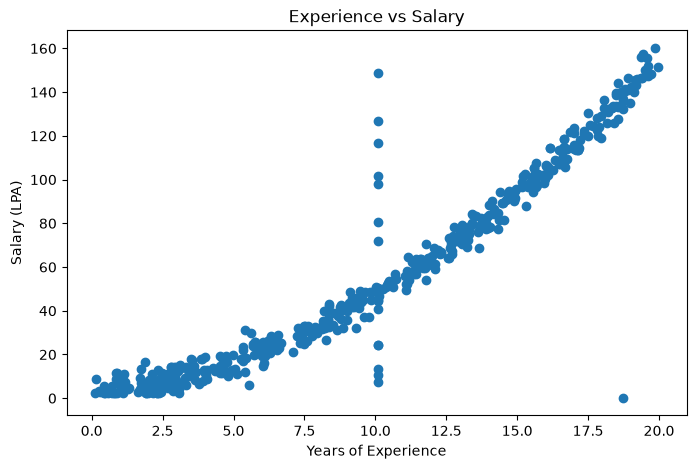

In [32]:

plt.figure(figsize=(8, 5))

plt.scatter(
    dataset['years_experience'],
    dataset['salary_lpa']
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary (LPA)")
plt.title("Experience vs Salary")
plt.show()

In [37]:
dataset.shape

(483, 2)

In [46]:
X=dataset[['years_experience']]
Y=dataset['salary_lpa']

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
xtrain,xtest,ytrain,ytest=train_test_split(
    X,Y,
    test_size=0.2,
    random_state=42
)
print("Training data:", xtrain.shape)
print("Testing data:", xtest.shape)

Training data: (386, 1)
Testing data: (97, 1)


In [49]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()

In [50]:
xtrain=scalar.fit_transform(xtrain)
xtest=scalar.transform(xtest)

In [51]:
from sklearn.linear_model import LinearRegression
linear=LinearRegression()

In [52]:
linear.fit(xtrain,ytrain)

linear_predict=linear.predict(xtest)

In [53]:
from sklearn.preprocessing import PolynomialFeatures

# Generate polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)

xtrain_poly = poly.fit_transform(xtrain)
xtest_poly = poly.transform(xtest)

# Train the polynomial model
poly_model = LinearRegression()
poly_model.fit(xtrain_poly, ytrain)

# Make predictions
poly_predictions = poly_model.predict(xtest_poly)

print("Polynomial Regression trained successfully!")

Polynomial Regression trained successfully!


In [55]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f} LPA")
    print(f"RMSE: {rmse:.2f} LPA")
    print(f"R²:   {r2:.4f}")

evaluate_model("Linear Regression", ytest, linear_predict)
evaluate_model("Polynomial Regression", ytest, poly_predictions)


Linear Regression
MAE:  8.41 LPA
RMSE: 10.68 LPA
R²:   0.9437

Polynomial Regression
MAE:  3.62 LPA
RMSE: 6.93 LPA
R²:   0.9763


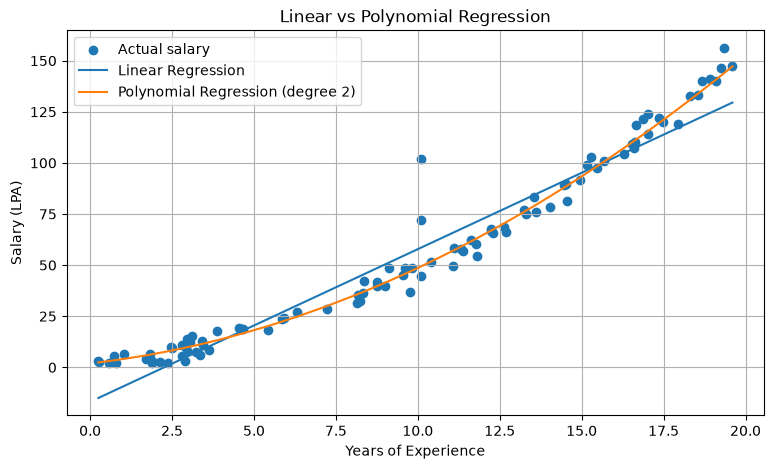

In [56]:
import matplotlib.pyplot as plt

# Recover original experience values for the test set
test_experience = scalar.inverse_transform(xtest).ravel()

# Sort points so the lines plot correctly
order = np.argsort(test_experience)

plt.figure(figsize=(9, 5))

plt.scatter(test_experience, ytest, label="Actual salary")
plt.plot(
    test_experience[order],
    linear_predict[order],
    label="Linear Regression"
)
plt.plot(
    test_experience[order],
    poly_predictions[order],
    label="Polynomial Regression (degree 2)"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary (LPA)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

In [59]:
# Enter years of experience
experience = 0

# Standardize the input using your existing scaler
experience_scaled = scalar.transform([[experience]])

# Convert the input into polynomial features
experience_poly = poly.transform(experience_scaled)

# Predict salary
predicted_salary = poly_model.predict(experience_poly)

print(f"Experience: {experience} years")
print(f"Predicted Salary: ₹{predicted_salary[0]:.2f} LPA")

Experience: 0 years
Predicted Salary: ₹1.95 LPA


/Users/arnav/python_ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
